# Часть 2. BCR: обработка MiXCR и анализ репертуара



MiXCR **4.7.0** был запущен на сервере  через **Slurm**, партиция `AMD9554-common`,

## 1. Загрузка результатов и воспроизводимость



In [ ]:
import os
import io
import json
import tarfile
import hashlib
import platform
from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
import yaml
from IPython.display import display, Image, Markdown
from repseq import clonosets as cl
from repseq import clone_filter as clf
from repseq import stats
from repseq import common_functions as common

if Path("/home/STUDY/FBMF").is_dir() and not os.environ.get("SLURM_JOB_ID"):
    raise RuntimeError("На сервере МФТИ запустите ядро внутри задания Slurm.")

B_SAMPLE = "DChu_T7_pbmc_d7COVID2_2"
B_CPU = 1
B_SEED = 100
B_CANDIDATES = [
    Path(os.environ.get("BCR_MIXCR_DIR", ".")),
    Path.cwd() / "BCR_results_161698",
    Path.cwd() / "outputs/bcr/mixcr/job_161698",
    Path.cwd().parent / "outputs/bcr/mixcr/job_161698",
    Path.home() / "Immune_homework/outputs/bcr/mixcr/job_161698",
]
B_RUN = next((p for p in B_CANDIDATES if (p / f"{B_SAMPLE}.clones_IGH.tsv").is_file()), None)
if B_RUN is None:
    archive = Path.cwd() / "BCR_results_161698.tar.gz"
    if not archive.is_file():
        raise FileNotFoundError("Для повторного запуска нужен BCR_results_161698.tar.gz или BCR_MIXCR_DIR.")
    target = Path.cwd() / "BCR_results_161698"
    target.mkdir(exist_ok=True)
    with tarfile.open(archive) as handle:
        for member in handle.getmembers():
            name = Path(member.name)
            if not member.isfile() or name.is_absolute() or len(name.parts) != 1 or name.name in [".", ".."]:
                raise ValueError("Неожиданный путь в архиве")
            (target / name.name).write_bytes(handle.extractfile(member).read())
    B_RUN = target

B_OUT = Path(os.environ.get("BCR_ANALYSIS_DIR", str(Path.cwd() / "BCR_analysis")))
B_OUT.mkdir(parents=True, exist_ok=True)
B_TSV = B_RUN / f"{B_SAMPLE}.clones_IGH.tsv"
B_RAW = pd.read_csv(B_TSV, sep="\t")
B_ALIGN = json.loads((B_RUN / f"{B_SAMPLE}.align.report.json").read_text())
B_REFINE = json.loads((B_RUN / f"{B_SAMPLE}.refine.report.json").read_text())
B_ASSEMBLE = json.loads((B_RUN / f"{B_SAMPLE}.assemble.report.json").read_text())
B_QC = json.loads((B_RUN / f"{B_SAMPLE}.qc.json").read_text())
B_PRESET = yaml.safe_load((B_RUN / "preset.yaml").read_text())
B_FILES = cl.find_all_mixcr_clonosets(str(B_RUN), chain="BCR", show_offtarget=True)
assert len(B_FILES) == 1 and set(B_FILES.chain) == {"IGH"}
assert B_RAW.cloneId.is_unique
assert len(B_RAW) == B_ASSEMBLE["clones"]
assert np.isclose(B_RAW.readCount.sum(), B_ASSEMBLE["readsInClones"])

aa_table = Path(stats.__file__).resolve().parent / "resourses/aa_property_table.txt"
if aa_table.is_file():
    stats.AA_PROPS_PATH = str(aa_table)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"font.family": "DejaVu Sans", "figure.dpi": 110})

def b_show(fig, name):
    fig.tight_layout()
    fig.savefig(B_OUT / f"{name}.png", dpi=160, bbox_inches="tight")
    fig.savefig(B_OUT / f"{name}.pdf", bbox_inches="tight")
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=110, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close(fig)

def b_fmt(value, digits=2):
    return f"{value:,.{digits}f}".replace(",", " ").replace(".", ",")

B_PROVENANCE = {
    "sample": B_SAMPLE,
    "slurm_job_id": 161698,
    "slurm_partition": "AMD9554-common",
    "mixcr_version": B_ALIGN["version"],
    "export_sha256": hashlib.sha256(B_TSV.read_bytes()).hexdigest(),
    "python": platform.python_version(),
    "packages": {p: version(p) for p in ["repseq", "numpy", "pandas", "scipy", "matplotlib", "seaborn"]},
    "count_column": "uniqueMoleculeCount",
    "functionality": "f",
    "seed": B_SEED,
    "downstream_execution": "Separate workspace; MiXCR upstream was run in Slurm on MIPT",
}
(B_OUT / "provenance.json").write_text(json.dumps(B_PROVENANCE, ensure_ascii=False, indent=2), encoding="utf-8")
display(pd.DataFrame({"Параметр": ["Образец", "Цепь", "MiXCR", "repseq", "Экспортировано клонотипов", "Сборка", "Разделение по V/J/C"], "Значение": [B_SAMPLE, "IGH", B_ALIGN["version"].split(";")[0], version("repseq"), len(B_RAW), "CDR3", "Да / Да / Да"]}))

,Параметр,Значение
0,Образец,DChu_T7_pbmc_d7COVID2_2
1,Цепь,IGH
2,MiXCR,4.7.0
3,repseq,0.1.3
4,Экспортировано клонотипов,42865
5,Сборка,CDR3
6,Разделение по V/J/C,Да / Да / Да


## 2. Контроль качества MiXCR

Проценты разных этапов имеют разные знаменатели. В частности, доля использованных при сборке прочтений в отчете MiXCR считается от входа в сборку после фильтрации, а не от исходного FASTQ. Поскольку чтение парное, исходные 938 889 записей в отчете соответствуют 938 889 парам R1/R2.

,Этап,Количество,% от исходного входа
0,Исходные пары R1/R2,938889,100.00
1,Распознан UMI-паттерн,935789,99.67
2,Успешно выровнено,865681,92.20
3,После коррекции и фильтрации тегов,782678,83.36
4,Использовано в клонотипах,764915,81.47


,Показатель MiXCR,Значение,Статус
0,Successfully aligned reads,92.2%,OK
1,Off target (non TCR/IG) reads,0.96%,OK
2,Reads with no V or J hits,5.32%,OK
3,Alignments that do not cover CDR3,0.82%,OK
4,Reads with no barcode,0.33%,OK
5,Reads dropped in tags error correction and fil...,9.59%,WARN
6,UMIs artificial diversity eliminated,6.99%,OK
7,Reads dropped in UMI error correction and whit...,0.0%,OK
8,Reads dropped in tags filtering,9.59%,WARN
9,Tag groups that do not cover CDR3,0.18%,OK


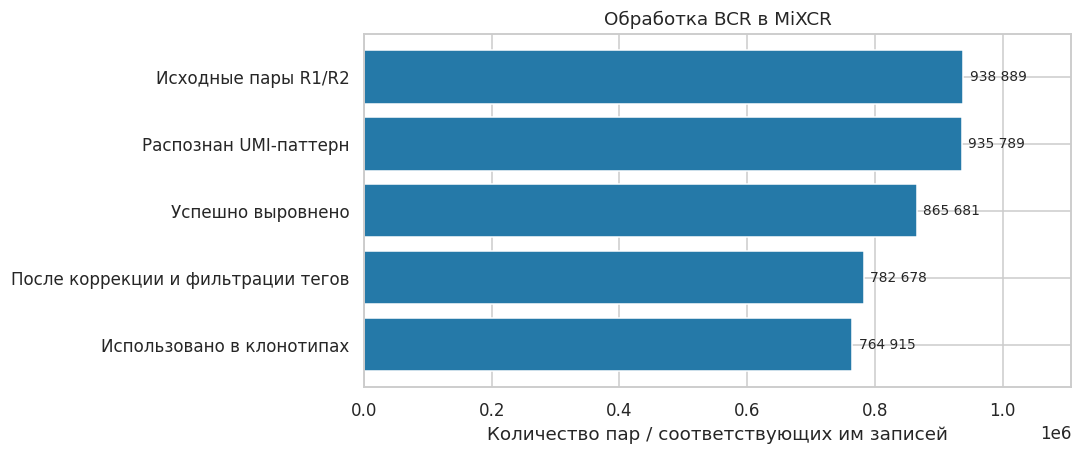

**Вывод по качеству.** Выровнено 92,20% исходных пар; UMI-паттерн распознан в 99,67%. Все выравнивания и все экспортированные клонотипы отнесены к IGH. Результат согласуется с выбранным UMI-пресетом, но сам по себе не заменяет описание лабораторного протокола.

После фильтрации тегов потеряно **83,003** выровненных записей, то есть **9,59%** от выровненного входа. Два пункта WARN с 9,59% описывают одну и ту же потерю на этом этапе; их не складываю. Порог в отчете фильтрации равен 3 прочтениям на группу UMI.

Еще один WARN — **3,726** групп с несколькими консенсусами, **3,59%** групп, содержащих собираемый участок. Это предупреждение о неоднозначности внутри групп штрихкодов; оно не означает, что ровно такая доля всех B-клеток ошибочна. Предупреждения сохраняю как ограничения, а не игнорирую.

В клонотипы вошло **97,73%** входа в сборку, но **81,47%** исходных пар. Эти проценты нельзя подменять друг другом.

In [ ]:
B_INPUT = B_ALIGN["totalReadsProcessed"]
B_ALIGNED = B_ALIGN["aligned"]
B_RETAINED = B_REFINE["correctionReport"]["outputRecords"]
B_USED = B_ASSEMBLE["readsInClones"]
B_STAGES = pd.DataFrame({
    "Этап": ["Исходные пары R1/R2", "Распознан UMI-паттерн", "Успешно выровнено", "После коррекции и фильтрации тегов", "Использовано в клонотипах"],
    "Количество": [B_INPUT, B_ALIGN["tagParsingReport"]["matched"], B_ALIGNED, B_RETAINED, B_USED],
})
B_STAGES["% от исходного входа"] = 100 * B_STAGES["Количество"] / B_INPUT
B_STAGES.to_csv(B_OUT / "mixcr_stages.csv", index=False)
display(B_STAGES.round(2))

B_QC_TABLE = pd.DataFrame([{"Показатель MiXCR": q["payload"].get("labelOverride", q["check"]["label"]), "Значение": q["payload"]["printedValue"], "Статус": q["status"]} for q in B_QC])
B_QC_TABLE.to_csv(B_OUT / "mixcr_qc.csv", index=False)
display(B_QC_TABLE)

fig, ax = plt.subplots(figsize=(10, 4.3))
ax.barh(B_STAGES["Этап"].iloc[::-1], B_STAGES["Количество"].iloc[::-1], color="#2579a8")
for i, value in enumerate(B_STAGES["Количество"].iloc[::-1]):
    ax.text(value + 10000, i, f"{value:,}".replace(",", " "), va="center", fontsize=9)
ax.set(xlabel="Количество пар / соответствующих им записей", xlim=(0, B_INPUT * 1.18), title="Обработка BCR в MiXCR")
b_show(fig, "01_mixcr_stages")

B_PRECLONE = B_ASSEMBLE["preCloneAssemblerReport"]
B_COLLISION_DENOM = B_PRECLONE["inputGroups"] - B_PRECLONE["groupsWithNoAssemblingFeature"]
B_LOST = B_ALIGNED - B_RETAINED
display(Markdown(f"""**Вывод по качеству.** Выровнено {b_fmt(100 * B_ALIGNED / B_INPUT)}% исходных пар; UMI-паттерн распознан в {b_fmt(100 * B_ALIGN['tagParsingReport']['matched'] / B_INPUT)}%. Все выравнивания и все экспортированные клонотипы отнесены к IGH. Результат согласуется с выбранным UMI-пресетом, но сам по себе не заменяет описание лабораторного протокола.

После фильтрации тегов потеряно **{B_LOST:,}** выровненных записей, то есть **{b_fmt(100 * B_LOST / B_ALIGNED)}%** от выровненного входа. Два пункта WARN с 9,59% описывают одну и ту же потерю на этом этапе; их не складываю. Порог в отчете фильтрации равен 3 прочтениям на группу UMI.

Еще один WARN — **{B_PRECLONE['tagConflicts']:,}** групп с несколькими консенсусами, **{b_fmt(100 * B_PRECLONE['tagConflicts'] / B_COLLISION_DENOM)}%** групп, содержащих собираемый участок. Это предупреждение о неоднозначности внутри групп штрихкодов; оно не означает, что ровно такая доля всех B-клеток ошибочна. Предупреждения сохраняю как ограничения, а не игнорирую.

В клонотипы вошло **{b_fmt(100 * B_USED / B_RETAINED)}%** входа в сборку, но **{b_fmt(100 * B_USED / B_INPUT)}%** исходных пар. Эти проценты нельзя подменять друг другом."""))

## 3. Продуктивность и выбор счетчика

Оставляю CDR3 без стоп-кодонов и сдвига рамки. Это стандартный фильтр продуктивности по CDR3, а не экспериментальная проверка активности антител. Для частот использую UMI-счетчик, а не `readCount`: ПЦР может давать разное число прочтений на исходную молекулу.

In [ ]:
B_STATS = stats.calc_clonoset_stats(B_FILES, cpu=B_CPU, verbose=False)
B_FILTER = clf.Filter(functionality="f", by_umi=True)
B_USABLE = B_FILTER.apply(B_RAW)
B_FUNCTIONAL_RAW = common.filter_by_functionality(B_RAW).copy()
B_N = int(B_USABLE["count"].sum())
assert len(B_USABLE) == len(B_FUNCTIONAL_RAW) == B_ASSEMBLE["clones"] - B_ASSEMBLE["clonalChainUsage"]["chains"]["IGH"]["nonFunctional"]
assert B_N == int(B_FUNCTIONAL_RAW.uniqueMoleculeCount.sum())
B_STATS.to_csv(B_OUT / "clonoset_stats.csv", index=False)
B_COUNTS = pd.DataFrame({
    "Показатель": ["Все клонотипы", "Продуктивные клонотипы", "Непродуктивные клонотипы", "Доля продуктивных клонотипов, %", "Сумма readCount: все", "Сумма readCount: продуктивные", "Сумма uniqueMoleculeCount: все", "Сумма uniqueMoleculeCount: продуктивные"],
    "Значение": [len(B_RAW), len(B_USABLE), len(B_RAW) - len(B_USABLE), 100 * len(B_USABLE) / len(B_RAW), B_RAW.readCount.sum(), B_FUNCTIONAL_RAW.readCount.sum(), B_RAW.uniqueMoleculeCount.sum(), B_N],
})
display(B_COUNTS.round(3))
B_COUNTS.to_csv(B_OUT / "count_summary.csv", index=False)
display(Markdown(f"""После фильтрации осталось **{len(B_USABLE):,} продуктивных клонотипов** и **{B_N:,} молекулярных наблюдений**, то есть суммы `uniqueMoleculeCount` по этим клонотипам. Продуктивные CDR3 составляют {b_fmt(100 * len(B_USABLE) / len(B_RAW))}% экспортированных клонотипов.

Сумма UMI-счетчиков по клонотипам не тождественна числу глобально уникальных последовательностей UMI: один штрихкод может встречаться в нескольких группах/клонотипах. Это согласуется с предупреждением о коллизиях. Число молекулярных наблюдений также **не равно числу B-клеток**."""))

,Показатель,Значение
0,Все клонотипы,42865.000
1,Продуктивные клонотипы,41630.000
2,Непродуктивные клонотипы,1235.000
3,"Доля продуктивных клонотипов, %",97.119
4,Сумма readCount: все,764915.000
5,Сумма readCount: продуктивные,755321.000
6,Сумма uniqueMoleculeCount: все,104172.000
7,Сумма uniqueMoleculeCount: продуктивные,102809.000


После фильтрации осталось **41,630 продуктивных клонотипов** и **102,809 молекулярных наблюдений**, то есть суммы `uniqueMoleculeCount` по этим клонотипам. Продуктивные CDR3 составляют 97,12% экспортированных клонотипов.

Сумма UMI-счетчиков по клонотипам не тождественна числу глобально уникальных последовательностей UMI: один штрихкод может встречаться в нескольких группах/клонотипах. Это согласуется с предупреждением о коллизиях. Число молекулярных наблюдений также **не равно числу B-клеток**.

## 4. Длины и свойства CDR3

Распределение длин взвешивается по молекулярным наблюдениям. Свойства пяти центральных аминокислот и всей CDR3 считаются теми же функциями `repseq`, что и в TCR-ноутбуке.

,mean_cdr3aa_len,mean_insert_size,zero_insert_freq,cdr3_5_charge,cdr3_5_kf4,cdr3_5_volume
0,18.1517,13.0413,0.0104,-0.0893,-0.5827,496.1866


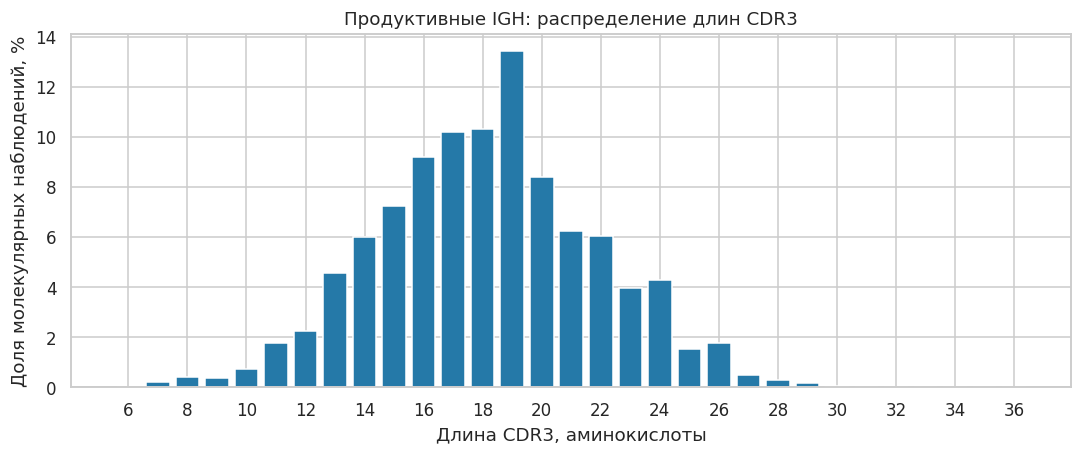

Средняя длина CDR3 — **18,15 aa**, наиболее частая — **19 aa**, диапазон — **6–36 aa**. Репертуар содержит CDR3 разной длины; один пик распределения не указывает на общую антигенную специфичность.

Показатели заряда, KF4 и объема описывают аминокислотный состав в шкалах `repseq`. Они не измеряют силу связывания антител. Оценка вставок основана на координатах V/D/J и не является оценкой SHM; для BCR она требует осторожности из-за неоднозначности D-выравниваний и мутаций.

In [ ]:
B_PROPERTIES = stats.calc_cdr3_properties(B_FILES, cl_filter=B_FILTER, iterations=1, cpu=B_CPU, verbose=False)
B_PROPERTIES["mean_cdr3aa_len"] = B_PROPERTIES["mean_cdr3nt_len"] / 3
B_LENGTHS = stats.cdr3_length_distributions(B_FILES, cl_filter=B_FILTER, seq_type="aa", cpu=B_CPU, verbose=False)
B_PROPERTIES.to_csv(B_OUT / "cdr3_properties.csv", index=False)
B_LENGTHS.to_csv(B_OUT / "cdr3_lengths.csv", index=False)
display(B_PROPERTIES[["mean_cdr3aa_len", "mean_insert_size", "zero_insert_freq", "cdr3_5_charge", "cdr3_5_kf4", "cdr3_5_volume"]].round(4))
fig, ax = plt.subplots(figsize=(10, 4.3))
ax.bar(B_LENGTHS.cdr3_length, 100 * B_LENGTHS.freq, color="#2579a8")
ax.set(xlabel="Длина CDR3, аминокислоты", ylabel="Доля молекулярных наблюдений, %", title="Продуктивные IGH: распределение длин CDR3")
ax.set_xticks(range(int(B_LENGTHS.cdr3_length.min()), int(B_LENGTHS.cdr3_length.max()) + 1, 2))
b_show(fig, "02_cdr3_lengths")
B_MODE_AA = int(B_LENGTHS.loc[B_LENGTHS.freq.idxmax(), "cdr3_length"])
display(Markdown(f"""Средняя длина CDR3 — **{b_fmt(B_PROPERTIES.mean_cdr3aa_len.iloc[0])} aa**, наиболее частая — **{B_MODE_AA} aa**, диапазон — **{int(B_USABLE.cdr3aa.str.len().min())}–{int(B_USABLE.cdr3aa.str.len().max())} aa**. Репертуар содержит CDR3 разной длины; один пик распределения не указывает на общую антигенную специфичность.

Показатели заряда, KF4 и объема описывают аминокислотный состав в шкалах `repseq`. Они не измеряют силу связывания антител. Оценка вставок основана на координатах V/D/J и не является оценкой SHM; для BCR она требует осторожности из-за неоднозначности D-выравниваний и мутаций."""))

## 5. Использование V- и J-генов

Из неоднозначных списков берется первый, наиболее высокий hit согласно преобразованию `repseq`; аллельный суффикс убирается. На рисунке показаны до 20 наиболее частых V-генов и все J-гены. Доли рассчитаны по молекулярным наблюдениям продуктивного клоносета.

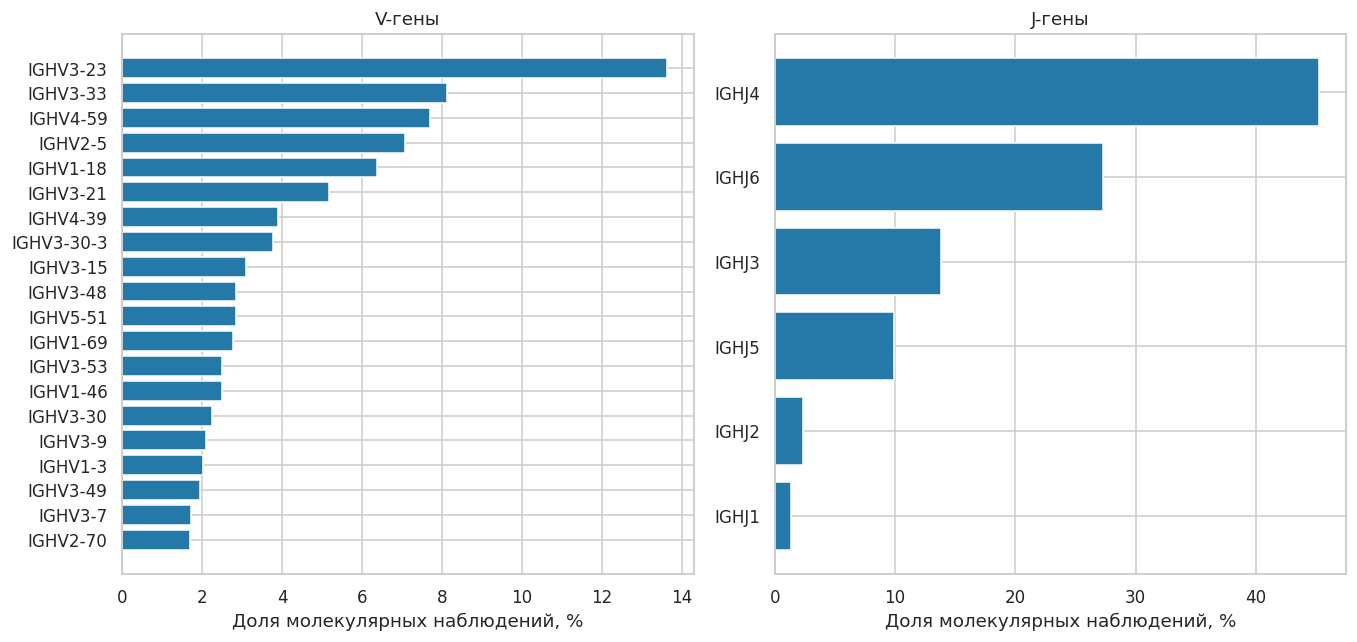

,v,% молекулярных наблюдений
22,IGHV3-23,13.612
25,IGHV3-33,8.120
49,IGHV4-59,7.697
14,IGHV2-5,7.061
1,IGHV1-18,6.376


,j,% молекулярных наблюдений
3,IGHJ4,45.269
5,IGHJ6,27.270
2,IGHJ3,13.798
4,IGHJ5,9.935
1,IGHJ2,2.374
0,IGHJ1,1.353


Наиболее частые V-гены: **IGHV3-23 (13,61%), IGHV3-33 (8,12%), IGHV4-59 (7,70%)**. Среди J-генов преобладают **IGHJ4 (45,27%), IGHJ6 (27,27%)**. Это описание использования сегментов в одном образце. Без контрольных образцов оно не доказывает обогащение или ответ на определенный антиген.

In [ ]:
B_V = stats.calc_segment_usage(B_FILES, segment="v", cl_filter=B_FILTER, cpu=B_CPU, verbose=False)
B_J = stats.calc_segment_usage(B_FILES, segment="j", cl_filter=B_FILTER, cpu=B_CPU, verbose=False)
B_V.to_csv(B_OUT / "v_usage.csv", index=False)
B_J.to_csv(B_OUT / "j_usage.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 6))
for frame, key, ax, top_n in [(B_V, "v", axes[0], 20), (B_J, "j", axes[1], 20)]:
    top = frame.nlargest(top_n, "usage").iloc[::-1]
    ax.barh(top[key], 100 * top.usage, color="#2579a8")
    ax.set(xlabel="Доля молекулярных наблюдений, %", title=f"{key.upper()}-гены")
b_show(fig, "03_vj_usage")
display(B_V.nlargest(5, "usage")[["v", "usage"]].assign(usage=lambda d: 100 * d.usage).rename(columns={"usage": "% молекулярных наблюдений"}).round(3))
display(B_J.nlargest(6, "usage")[["j", "usage"]].assign(usage=lambda d: 100 * d.usage).rename(columns={"usage": "% молекулярных наблюдений"}).round(3))
B_TOP_V = B_V.nlargest(3, "usage")
B_TOP_J = B_J.nlargest(2, "usage")
display(Markdown("Наиболее частые V-гены: **" + ", ".join(f"{r.v} ({b_fmt(100*r.usage)}%)" for r in B_TOP_V.itertuples()) + "**. Среди J-генов преобладают **" + ", ".join(f"{r.j} ({b_fmt(100*r.usage)}%)" for r in B_TOP_J.itertuples()) + "**. Это описание использования сегментов в одном образце. Без контрольных образцов оно не доказывает обогащение или ответ на определенный антиген."))

## 6. Изотипы тяжелой цепи

Использую столбец `isotype` исходного экспорта MiXCR. Сравниваю доли по числу клонотипов и по молекулярным наблюдениям. Эти две доли отвечают на разные вопросы и не являются долями клеточных популяций.

,isotype_label,clonotypes,molecules,clonotype_percent,molecule_percent
8,IgM,22340,42410,53.6632,41.2513
2,IgD,17131,22726,41.1506,22.1051
3,IgG1,971,18911,2.3325,18.3943
0,IgA1,737,11416,1.7704,11.1041
5,IgG3,99,3191,0.2378,3.1038
1,IgA2,176,2673,0.4228,2.6000
4,IgG2,139,1422,0.3339,1.3831
9,Не определен,31,35,0.0745,0.0340
6,IgG4,5,24,0.0120,0.0233
7,IgGP,1,1,0.0024,0.0010


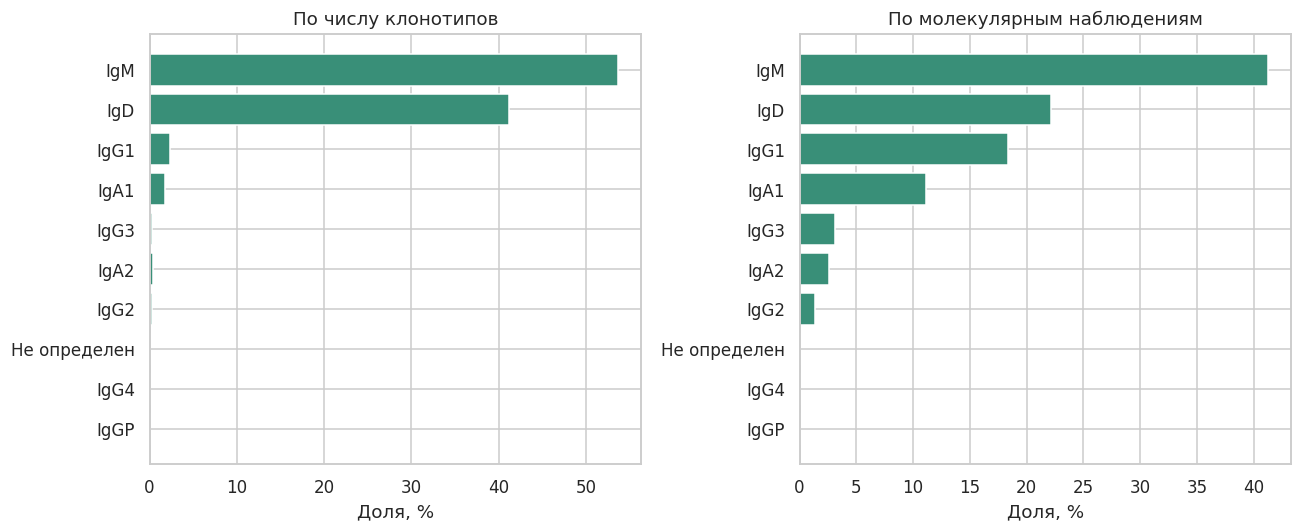

IgM и IgD суммарно дают **63,36% молекулярных наблюдений**, а IgG/IgA — **36,61%**. При этом картина по числу клонотипов отличается от картины по молекулярным частотам. Это согласуется с различным размером клонов и/или уровнем транскрипции иммуноглобулинов; разделить эти причины по данному bulk RNA-образцу нельзя.

Наличие IgG/IgA совместимо с присутствием переключенных классов иммуноглобулинов, но не доказывает, что эти антитела специфичны к SARS-CoV-2. Единственная запись с IgE в полном экспорте непродуктивна и после фильтрации отсутствует. IgGP оставлена как редкая аннотация экспорта; по ней не делаю вывод о наличии отдельной функциональной клеточной популяции. Неопределенные C-hit не исключаются из знаменателя.

In [ ]:
B_ISOTYPES = B_FUNCTIONAL_RAW.assign(isotype_label=B_FUNCTIONAL_RAW.isotype.fillna("Не определен")).groupby("isotype_label", dropna=False).agg(clonotypes=("cloneId", "size"), molecules=("uniqueMoleculeCount", "sum")).reset_index()
B_ISOTYPES["clonotype_percent"] = 100 * B_ISOTYPES.clonotypes / len(B_FUNCTIONAL_RAW)
B_ISOTYPES["molecule_percent"] = 100 * B_ISOTYPES.molecules / B_N
B_ISOTYPES = B_ISOTYPES.sort_values("molecules", ascending=False)
B_ISOTYPES.to_csv(B_OUT / "isotype_usage.csv", index=False)
display(B_ISOTYPES.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ordered = B_ISOTYPES.iloc[::-1]
for ax, column, title in [(axes[0], "clonotype_percent", "По числу клонотипов"), (axes[1], "molecule_percent", "По молекулярным наблюдениям")]:
    ax.barh(ordered.isotype_label, ordered[column], color="#398f78")
    ax.set(xlabel="Доля, %", title=title)
b_show(fig, "04_isotypes")
B_M_D = B_ISOTYPES.loc[B_ISOTYPES.isotype_label.isin(["IgM", "IgD"]), "molecule_percent"].sum()
B_G_A = B_ISOTYPES.loc[B_ISOTYPES.isotype_label.str.match(r"Ig[GA][1-4]$"), "molecule_percent"].sum()
display(Markdown(f"""IgM и IgD суммарно дают **{b_fmt(B_M_D)}% молекулярных наблюдений**, а IgG/IgA — **{b_fmt(B_G_A)}%**. При этом картина по числу клонотипов отличается от картины по молекулярным частотам. Это согласуется с различным размером клонов и/или уровнем транскрипции иммуноглобулинов; разделить эти причины по данному bulk RNA-образцу нельзя.

Наличие IgG/IgA совместимо с присутствием переключенных классов иммуноглобулинов, но не доказывает, что эти антитела специфичны к SARS-CoV-2. Единственная запись с IgE в полном экспорте непродуктивна и после фильтрации отсутствует. IgGP оставлена как редкая аннотация экспорта; по ней не делаю вывод о наличии отдельной функциональной клеточной популяции. Неопределенные C-hit не исключаются из знаменателя."""))

## 7. Альфа-разнообразие и распределение частот

Для одного образца сохраняю полный продуктивный клоносет: нет необходимости уменьшать данные до глубины другого донора. Shannon использует натуральный логарифм. Клональность определяется как `1 − Shannon / ln(число клонотипов)`.

,Метрика,Значение
0,Наблюдаемое число клонотипов,41630.00000
1,Shannon,9.35245
2,exp(Shannon),11527.02733
3,Клональность,0.12073
4,Обратный индекс Simpson,1365.91833
5,Chao1,84612.76359
6,Good's coverage,0.72702
7,Доля крупнейшего клонотипа,0.01525


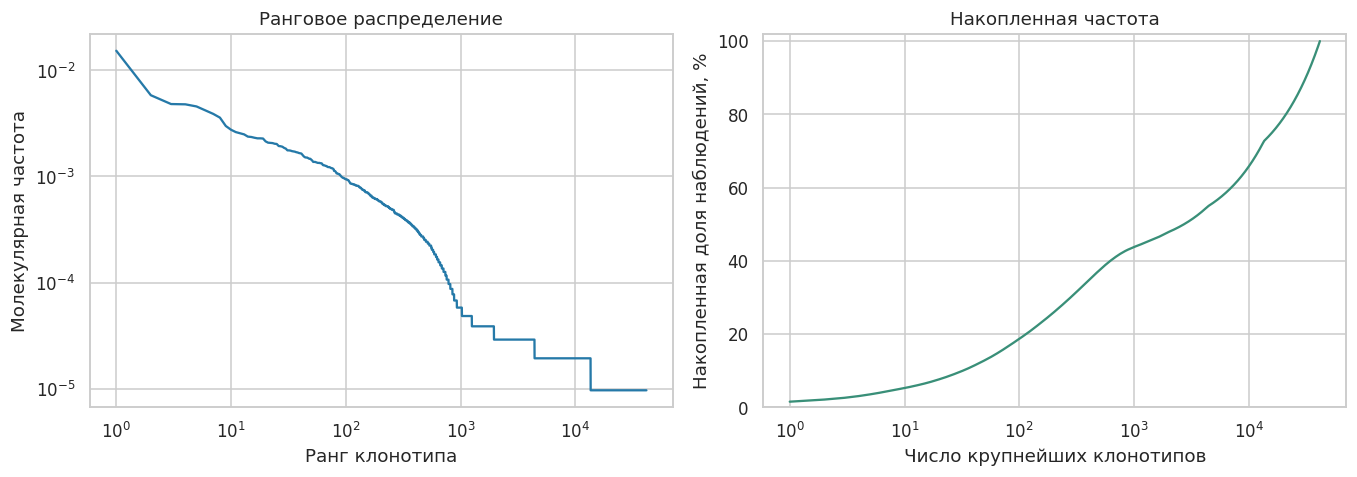

,cdr3aa,v,j,c,molecular_observations,freq
0,CARDRRTGLWSGYGYMDVW,IGHV3-33,IGHJ6,IGHG3,1568,0.015252
1,CARSDMLRFVEWTGSYQRFHMDVW,IGHV4-61,IGHJ6,IGHA1,598,0.005817
2,CARGGDPRVVVAATDAFDFW,IGHV1-46,IGHJ3,IGHA1,494,0.004805
3,CARDPNYDFWSGGDMNVW,IGHV3-21,IGHJ6,IGHM,491,0.004776
4,CAHSPASQGHFLMTFGGLIIPHFDSW,IGHV2-5,IGHJ4,IGHM,469,0.004562
5,CARRERFWSGYYTGREMIAFDIW,IGHV1-18,IGHJ3,IGHM,430,0.004183
6,CARDRRTGIWSGYGYMDVW,IGHV3-33,IGHJ6,IGHG1,399,0.003881
7,CTTDLDYYDSSGYRFDCW,IGHV3-15,IGHJ4,IGHM,368,0.003579
8,CARDRCSDNSCDSGAEYFQHW,IGHV3-33,IGHJ1,IGHA2,307,0.002986
9,CARDRRTGLWSGYGYMDVW,IGHV3-33,IGHJ6,IGHG1,283,0.002753


Shannon равен **9,352**, клональность — **0,1207**. Самый частый клонотип составляет **1,53%**, первые 10 — **5,26%**, первые 100 — **18,68%** молекулярных наблюдений. Значит, частоты неравномерны, но весь репертуар не сводится к одному доминирующему клону.

Клонотипов с одним молекулярным наблюдением — **28,065**, или **67,42%** от всех продуктивных клонотипов. Поэтому оценка полного богатства чувствительна к редким вариантам, ошибкам и порогам фильтрации. Chao1 ≈ **84 613** — формальная оценка богатства по этому клоносету, а не точное число клонов или клеток у донора. Good's coverage не является процентом всех существующих у человека клонотипов.

In [ ]:
B_DIVERSITY = stats.calc_diversity_stats(B_FILES, cl_filter=B_FILTER, iterations=1, cpu=B_CPU, verbose=False)
B_DIVERSITY.to_csv(B_OUT / "diversity_full.csv", index=False)
B_DIV = B_DIVERSITY.iloc[0]
B_ALPHA_TABLE = pd.DataFrame({"Метрика": ["Наблюдаемое число клонотипов", "Shannon", "exp(Shannon)", "Клональность", "Обратный индекс Simpson", "Chao1", "Good's coverage", "Доля крупнейшего клонотипа"], "Значение": [B_DIV.diversity, B_DIV.shannon_wiener, np.exp(B_DIV.shannon_wiener), B_DIV.clonality, B_DIV.inverse_simpson, B_DIV.chao1, B_DIV.goods_coverage, B_DIV.berger_parker]})
display(B_ALPHA_TABLE.round(5))
B_RANKED = B_USABLE.sort_values("count", ascending=False).reset_index(drop=True)
B_CUMULATIVE = 100 * B_RANKED["count"].cumsum() / B_N
B_SINGLETONS = int(B_USABLE["count"].eq(1).sum())
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))
axes[0].plot(np.arange(1, len(B_RANKED) + 1), B_RANKED["count"] / B_N, color="#2579a8")
axes[0].set(xscale="log", yscale="log", xlabel="Ранг клонотипа", ylabel="Молекулярная частота", title="Ранговое распределение")
axes[1].plot(np.arange(1, len(B_RANKED) + 1), B_CUMULATIVE, color="#398f78")
axes[1].set(xscale="log", xlabel="Число крупнейших клонотипов", ylabel="Накопленная доля наблюдений, %", title="Накопленная частота", ylim=(0, 102))
b_show(fig, "05_clone_frequencies")
display(B_RANKED.head(10)[["cdr3aa", "v", "j", "c", "count", "freq"]].rename(columns={"count": "molecular_observations"}))
B_TOP10 = float(B_CUMULATIVE.iloc[9])
B_TOP100 = float(B_CUMULATIVE.iloc[99])
display(Markdown(f"""Shannon равен **{b_fmt(B_DIV.shannon_wiener, 3)}**, клональность — **{b_fmt(B_DIV.clonality, 4)}**. Самый частый клонотип составляет **{b_fmt(100 * B_DIV.berger_parker)}%**, первые 10 — **{b_fmt(B_TOP10)}%**, первые 100 — **{b_fmt(B_TOP100)}%** молекулярных наблюдений. Значит, частоты неравномерны, но весь репертуар не сводится к одному доминирующему клону.

Клонотипов с одним молекулярным наблюдением — **{B_SINGLETONS:,}**, или **{b_fmt(100 * B_SINGLETONS / len(B_USABLE))}%** от всех продуктивных клонотипов. Поэтому оценка полного богатства чувствительна к редким вариантам, ошибкам и порогам фильтрации. Chao1 ≈ **{b_fmt(B_DIV.chao1, 0)}** — формальная оценка богатства по этому клоносету, а не точное число клонов или клеток у донора. Good's coverage не является процентом всех существующих у человека клонотипов."""))

## 8. Конвергенция

Использую отношение числа уникальных нуклеотидных вариантов к числу уникальных аминокислотных вариантов CDR3; дополнительно считаю варианты с учетом V и V/J. В BCR разные нуклеотидные варианты одной CDR3aa могут отражать не только конвергентную рекомбинацию, но и синонимичные мутации. Эта метрика сама по себе не восстанавливает родство B-клеток.

In [ ]:
B_CONVERGENCE = stats.calc_convergence(B_FILES, cl_filter=B_FILTER, iterations=1, cpu=B_CPU, verbose=False)
B_CONVERGENCE.to_csv(B_OUT / "convergence.csv", index=False)
display(B_CONVERGENCE.round(6))
B_DEFINITIONS = pd.DataFrame({"Определение": ["Экспортированный продуктивный клонотип CDR3 + V/J/C", "CDR3nt + V/J без разделения по C", "Только CDR3nt", "Только CDR3aa"], "Число": [len(B_USABLE), len(B_USABLE.drop_duplicates(["cdr3nt", "v", "j"])), B_USABLE.cdr3nt.nunique(), B_USABLE.cdr3aa.nunique()]})
display(B_DEFINITIONS)
B_DEFINITIONS.to_csv(B_OUT / "clonotype_definitions.csv", index=False)
B_POOLED_COUNTS = B_USABLE.groupby(["cdr3nt", "v", "j"], dropna=False)["count"].sum()
B_POOLED_DIV = pd.DataFrame([common.diversity_metrics(B_POOLED_COUNTS)])
assert B_POOLED_COUNTS.sum() == B_N
assert int(B_POOLED_DIV.diversity.iloc[0]) == int(B_DEFINITIONS.iloc[1]["Число"])
B_POOLED_DIV.to_csv(B_OUT / "diversity_ntVJ_without_C.csv", index=False)
B_C_DEFINITION = pd.concat([B_DIVERSITY.assign(definition="CDR3nt + V/J/C"), B_POOLED_DIV.assign(definition="CDR3nt + V/J, без C")], ignore_index=True)
display(B_C_DEFINITION[["definition", "diversity", "shannon_wiener", "clonality"]].round(5))
display(Markdown(f"""Конвергенция CDR3aa равна **{b_fmt(B_CONVERGENCE.convergence.iloc[0], 4)}**, а с учетом V/J — **{b_fmt(B_CONVERGENCE.convergence_vj.iloc[0], 4)}**. Значение выше 1 означает наличие нескольких нуклеотидных вариантов, кодирующих одинаковую аминокислотную последовательность. По одной этой таблице нельзя установить, возникли ли они независимо или в результате мутаций внутри B-клеточной линии.

В MiXCR этого запуска включено разделение клонов по C. При объединении одинаковых CDR3nt + V/J число клонотипов уменьшается с **{len(B_USABLE):,} до {int(B_POOLED_DIV.diversity.iloc[0]):,}**; Shannon меняется с **{b_fmt(B_DIV.shannon_wiener, 3)} до {b_fmt(B_POOLED_DIV.shannon_wiener.iloc[0], 3)}**. Это заметное влияние определения клонотипа. При таком объединении суммируются экспортированные молекулярные наблюдения; глобально уникальные UMI из агрегированной таблицы восстановить нельзя.

Основные метрики выше описывают экспортированные клонотипы V/J/C. Число строк экспорта, число уникальных CDR3 и число B-клеточных линий нельзя автоматически приравнивать."""))

,sample_id,chain,convergence,convergence_v,convergence_vj
0,DChu_T7_pbmc_d7COVID2_2,IGH,1.008966,1.008599,1.008588


,Определение,Число
0,Экспортированный продуктивный клонотип CDR3 + ...,41630
1,CDR3nt + V/J без разделения по C,34292
2,Только CDR3nt,34210
3,Только CDR3aa,33906


,definition,diversity,shannon_wiener,clonality
0,CDR3nt + V/J/C,41630.0,9.35245,0.12073
1,"CDR3nt + V/J, без C",34292.0,9.19422,0.11955


Конвергенция CDR3aa равна **1,0090**, а с учетом V/J — **1,0086**. Значение выше 1 означает наличие нескольких нуклеотидных вариантов, кодирующих одинаковую аминокислотную последовательность. По одной этой таблице нельзя установить, возникли ли они независимо или в результате мутаций внутри B-клеточной линии.

В MiXCR этого запуска включено разделение клонов по C. При объединении одинаковых CDR3nt + V/J число клонотипов уменьшается с **41,630 до 34,292**; Shannon меняется с **9,352 до 9,194**. Это заметное влияние определения клонотипа. При таком объединении суммируются экспортированные молекулярные наблюдения; глобально уникальные UMI из агрегированной таблицы восстановить нельзя.

Основные метрики выше описывают экспортированные клонотипы V/J/C. Число строк экспорта, число уникальных CDR3 и число B-клеточных линий нельзя автоматически приравнивать.

## 9. Rarefaction: достаточно ли глубины

Кривую строю по продуктивным молекулярным наблюдениям, с фиксированным seed и усреднением трех случайных подвыборок на промежуточных глубинах. Это техническое повторение даунсэмплинга одного образца, а не три биологических образца.

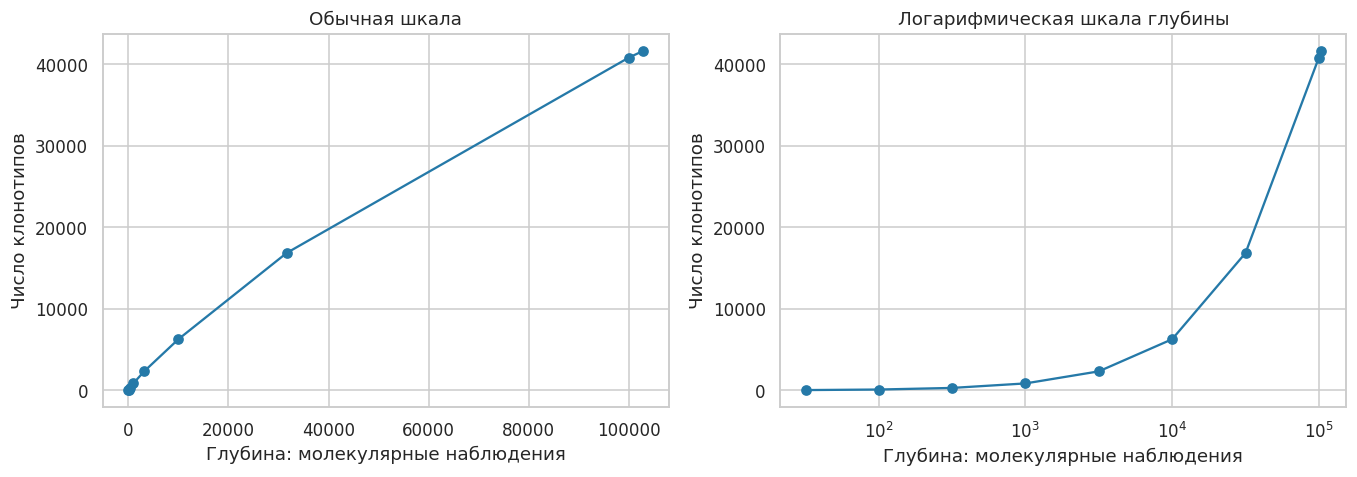

,sample_id,chain,rarefaction_depth,diversity
4,DChu_T7_pbmc_d7COVID2_2,IGH,3162,2327.000
5,DChu_T7_pbmc_d7COVID2_2,IGH,10000,6269.667
6,DChu_T7_pbmc_d7COVID2_2,IGH,31623,16848.000
7,DChu_T7_pbmc_d7COVID2_2,IGH,100000,40828.000
8,DChu_T7_pbmc_d7COVID2_2,IGH,102809,41630.000


При полной глубине **102,809** наблюдений обнаружено **41,630** продуктивных клонотипов. На последнем участке прирост составляет примерно **0,286 нового клонотипа на одно дополнительное наблюдение**. Вместе с большой долей синглтонов это указывает, что кривая еще не достигла полного плато. Дополнительное секвенирование могло бы выявить редкие варианты; точное полное богатство по этому образцу не установлено.

In [ ]:
B_RARE = stats.calc_rarefaction_curve(B_FILES, cl_filter=B_FILTER, iterations=3, seed=B_SEED, cpu=B_CPU, verbose=False).sort_values("rarefaction_depth")
B_RARE.to_csv(B_OUT / "rarefaction.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))
for ax, log in zip(axes, [False, True]):
    ax.plot(B_RARE.rarefaction_depth, B_RARE.diversity, marker="o", color="#2579a8")
    if log:
        ax.set_xscale("log")
    ax.set(xlabel="Глубина: молекулярные наблюдения", ylabel="Число клонотипов", title="Логарифмическая шкала глубины" if log else "Обычная шкала")
b_show(fig, "06_rarefaction")
B_TAIL = B_RARE.tail(2)
B_SLOPE = float(np.diff(B_TAIL.diversity)[0] / np.diff(B_TAIL.rarefaction_depth)[0])
assert int(B_RARE.iloc[-1].rarefaction_depth) == B_N
assert int(B_RARE.iloc[-1].diversity) == len(B_USABLE)
display(B_RARE.tail(5).round(3))
display(Markdown(f"""При полной глубине **{B_N:,}** наблюдений обнаружено **{len(B_USABLE):,}** продуктивных клонотипов. На последнем участке прирост составляет примерно **{b_fmt(B_SLOPE, 3)} нового клонотипа на одно дополнительное наблюдение**. Вместе с большой долей синглтонов это указывает, что кривая еще не достигла полного плато. Дополнительное секвенирование могло бы выявить редкие варианты; точное полное богатство по этому образцу не установлено."""))

## 10. Влияние глубины и выбора счетчика

Повторяю метрики при 10 000 и 50 000 молекулярных наблюдений. Для каждой глубины усредняю три подвыборки; seed задан функции расчета, а не жестко закреплен в самом фильтре, чтобы подвыборки различались. Отдельно сравниваю полный клоносет при весах по прочтениям и по молекулам.

Calcultating stats for original clonosets
_________________________________________
Calcultating stats for original clonosets
_________________________________________


,molecular_depth,diversity,shannon_wiener,clonality,berger_parker
0,10000,6245.00000,8.23038,0.05826,0.01450
1,50000,24356.66667,9.06222,0.10280,0.01503
2,102809,41630.00000,9.35245,0.12073,0.01525


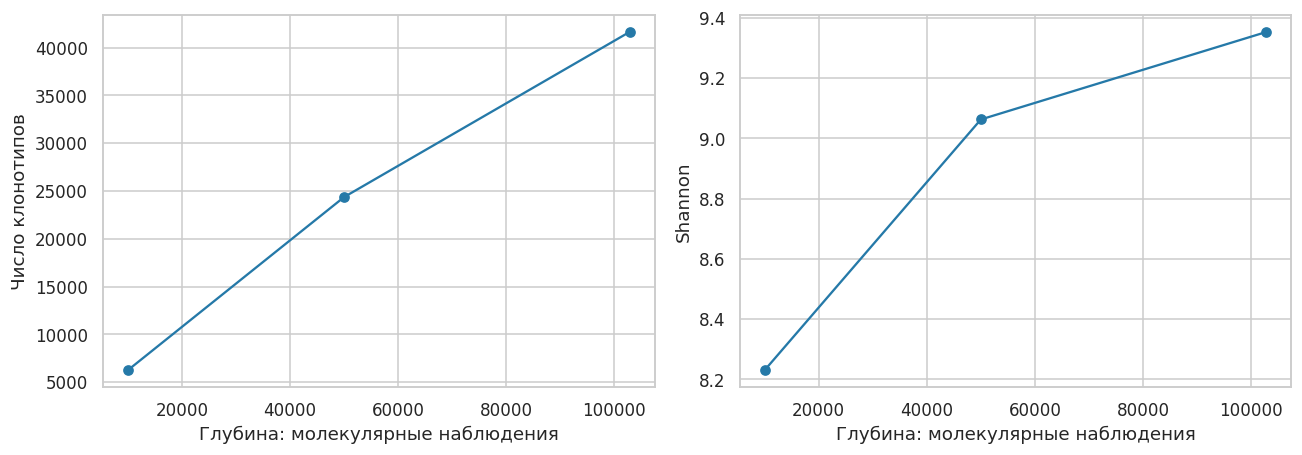

,weight,diversity,shannon_wiener,clonality,berger_parker
0,uniqueMoleculeCount,41630.0,9.35245,0.12073,0.01525
1,readCount,41630.0,9.28233,0.12732,0.01490


При глубине 10 000 обнаружено в среднем **6 245,0** клонотипа, при 50 000 — **24 356,7**, а при полном входе — **41,630**. Снижение наблюдаемого разнообразия при даунсэмплинге ожидаемо: редкие варианты теряются. Поэтому сравнивать разные образцы без учета глубины нельзя.

При весах по прочтениям Shannon равен **9,282**, при весах по молекулам — **9,352**. Количество строк клонотипов не меняется, но меняются их веса и метрики равномерности. Основные выводы строю по молекулярному счетчику. Сравнение двух счетчиков одного образца не является сравнением двух биологических повторов.

In [ ]:
B_DEPTH_ROWS = []
for depth in [10000, 50000]:
    selected_filter = clf.Filter(functionality="f", by_umi=True, downsample=depth)
    frame = stats.calc_diversity_stats(B_FILES, cl_filter=selected_filter, iterations=3, seed=B_SEED, cpu=B_CPU, verbose=False)
    B_DEPTH_ROWS.append(frame.assign(molecular_depth=depth))
B_DEPTH_ROWS.append(B_DIVERSITY.assign(molecular_depth=B_N))
B_DEPTHS = pd.concat(B_DEPTH_ROWS, ignore_index=True)
B_DEPTHS.to_csv(B_OUT / "depth_sensitivity.csv", index=False)
display(B_DEPTHS[["molecular_depth", "diversity", "shannon_wiener", "clonality", "berger_parker"]].round(5))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for ax, metric, label in [(axes[0], "diversity", "Число клонотипов"), (axes[1], "shannon_wiener", "Shannon")]:
    ax.plot(B_DEPTHS.molecular_depth, B_DEPTHS[metric], marker="o", color="#2579a8")
    ax.set(xlabel="Глубина: молекулярные наблюдения", ylabel=label)
b_show(fig, "07_depth_sensitivity")

B_READ_DIV = stats.calc_diversity_stats(B_FILES, cl_filter=clf.Filter(functionality="f", by_umi=False), iterations=1, cpu=B_CPU, verbose=False)
B_COUNTERS = pd.concat([B_DIVERSITY.assign(weight="uniqueMoleculeCount"), B_READ_DIV.assign(weight="readCount")], ignore_index=True)
B_COUNTERS.to_csv(B_OUT / "counter_comparison.csv", index=False)
display(B_COUNTERS[["weight", "diversity", "shannon_wiener", "clonality", "berger_parker"]].round(5))
display(Markdown(f"""При глубине 10 000 обнаружено в среднем **{b_fmt(B_DEPTHS.iloc[0].diversity, 1)}** клонотипа, при 50 000 — **{b_fmt(B_DEPTHS.iloc[1].diversity, 1)}**, а при полном входе — **{len(B_USABLE):,}**. Снижение наблюдаемого разнообразия при даунсэмплинге ожидаемо: редкие варианты теряются. Поэтому сравнивать разные образцы без учета глубины нельзя.

При весах по прочтениям Shannon равен **{b_fmt(B_READ_DIV.shannon_wiener.iloc[0], 3)}**, при весах по молекулам — **{b_fmt(B_DIV.shannon_wiener, 3)}**. Количество строк клонотипов не меняется, но меняются их веса и метрики равномерности. Основные выводы строю по молекулярному счетчику. Сравнение двух счетчиков одного образца не является сравнением двух биологических повторов."""))

## 11. Почему здесь нет межобразцовых F2 и MDS

В домашнем BCR-архиве один образец. Поэтому содержательное сравнение репертуаров между донорами и MDS по образцам выполнить нельзя. R1/R2 — парные чтения, а изотипы одного образца также не заменяют независимых доноров. В части TCR F2 и MDS рассчитаны, потому что там действительно есть несколько доноров и возрастные группы.

Не строю SHM-деревья и не оцениваю процент соматических мутаций по одному экспорту CDR3: выбранная сборка и таблица не содержат полноразмерных V-последовательностей для такого анализа. Похожие CDR3 и совпадение V/J не доказывают ни общее происхождение, ни одинаковую антигенную специфичность.

## 12. Итог по BCR

In [ ]:
B_NUMBERS = {
    "input_pairs": B_INPUT,
    "aligned_pairs": B_ALIGNED,
    "aligned_percent": 100 * B_ALIGNED / B_INPUT,
    "exported_clonotypes": len(B_RAW),
    "productive_clonotypes": len(B_USABLE),
    "productive_ntVJ_without_C": int(B_POOLED_DIV.diversity.iloc[0]),
    "productive_molecular_observations": B_N,
    "shannon": float(B_DIV.shannon_wiener),
    "clonality": float(B_DIV.clonality),
    "top_clone_percent": 100 * float(B_DIV.berger_parker),
    "top10_percent": B_TOP10,
    "top100_percent": B_TOP100,
    "mean_cdr3aa_length": float(B_PROPERTIES.mean_cdr3aa_len.iloc[0]),
    "mode_cdr3aa_length": B_MODE_AA,
    "singleton_clonotypes": B_SINGLETONS,
    "IgM_IgD_molecular_percent": float(B_M_D),
    "IgG_IgA_molecular_percent": float(B_G_A),
    "last_rarefaction_slope": B_SLOPE,
}
(B_OUT / "result_numbers.json").write_text(json.dumps(B_NUMBERS, ensure_ascii=False, indent=2), encoding="utf-8")
display(Markdown(f"""Из **{B_INPUT:,} пар прочтений** после обработки MiXCR получено **{len(B_RAW):,} клонотипов IGH**, из которых **{len(B_USABLE):,}** имеют продуктивную CDR3. Для последующего анализа использованы **{B_N:,} молекулярных наблюдений**.

Средняя длина CDR3 составила **{b_fmt(B_PROPERTIES.mean_cdr3aa_len.iloc[0])} aa**. Репертуар разнообразен, но частоты неравномерны: Shannon **{b_fmt(B_DIV.shannon_wiener, 3)}**, доля крупнейшего клонотипа **{b_fmt(100 * B_DIV.berger_parker)}%**. В молекулярных частотах заметны как IgM/IgD, так и IgG/IgA. Большая доля редких клонотипов и продолжающийся рост rarefaction показывают неполное насыщение.

Ограничения: один образец, отсутствие контрольной группы, предупреждения о коллизиях UMI и фильтрации, зависимость результатов от определения клонотипа и счетчика. Поэтому по этим данным нельзя доказать специфичность к SARS-CoV-2, оценить число B-клеток у донора или восстановить B-клеточные линии происхождения."""))

Из **938,889 пар прочтений** после обработки MiXCR получено **42,865 клонотипов IGH**, из которых **41,630** имеют продуктивную CDR3. Для последующего анализа использованы **102,809 молекулярных наблюдений**.

Средняя длина CDR3 составила **18,15 aa**. Репертуар разнообразен, но частоты неравномерны: Shannon **9,352**, доля крупнейшего клонотипа **1,53%**. В молекулярных частотах заметны как IgM/IgD, так и IgG/IgA. Большая доля редких клонотипов и продолжающийся рост rarefaction показывают неполное насыщение.

Ограничения: один образец, отсутствие контрольной группы, предупреждения о коллизиях UMI и фильтрации, зависимость результатов от определения клонотипа и счетчика. Поэтому по этим данным нельзя доказать специфичность к SARS-CoV-2, оценить число B-клеток у донора или восстановить B-клеточные линии происхождения.